In [92]:
# Import the Data 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Load the dataset
df = pd.read_csv("../data/train.csv")

# Display the first few rows of the dataset
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [93]:
# Information about the dataset
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


In [94]:
# Remove duplicates
df.drop_duplicates(inplace=True)


# Check for missing values
df.isnull().sum()

# Keep missing postal codes because they are not required
# for the current sales analysis.

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [95]:
# Check how many rows we have before cleaning
print("Rows remaining:", len(df))

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())



Rows remaining: 9800
Duplicate rows: 0


In [97]:
# Sales by Region
sales_by_region = df.groupby('Region')["Sales"].sum().sort_values(ascending = False)
print(sales_by_region)


Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


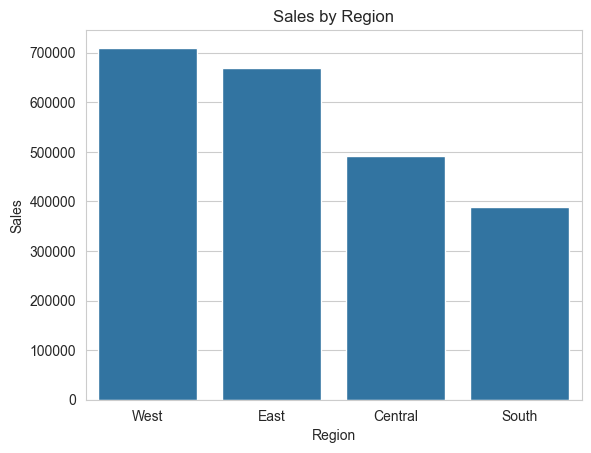

In [98]:
# Visualize Sales by Region
sns.barplot(data = sales_by_region.reset_index(), x = "Region", y = "Sales")
plt.title("Sales by Region")
plt.show()

In [99]:
# Calculate by Sales Product Category
sales_by_category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print(sales_by_category)

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


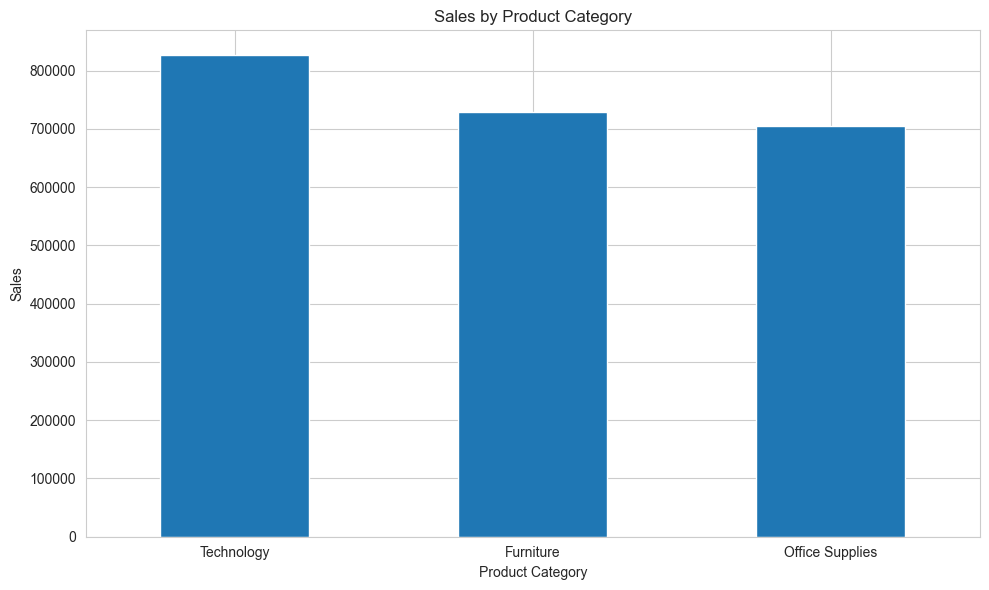

In [100]:
# Visualize Sales Product Category
sales_by_category.plot(kind = "bar", figsize=(10, 6))
plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [101]:
# Sales over Time 
df["Order Date"] = pd.to_datetime(df["Order Date"], format = "mixed")
df["Month"] = df["Order Date"].dt.to_period("M")
sales_over_time = df.groupby("Month")["Sales"].sum()

print(sales_over_time)


Month
2015-01    28828.2540
2015-02    12588.4840
2015-03    54027.6920
2015-04    24710.0160
2015-05    29520.4900
2015-06    29181.3346
2015-07    35194.5580
2015-08    37349.2655
2015-09    65956.3998
2015-10    34561.9470
2015-11    64369.4565
2015-12    63568.3107
2016-01    29347.3864
2016-02    20728.3520
2016-03    34489.6776
2016-04    38056.9685
2016-05    30761.5585
2016-06    28515.9082
2016-07    28573.3100
2016-08    49076.9300
2016-09    65352.9970
2016-10    31631.8890
2016-11    50009.1450
2016-12    52891.8832
2017-01    38048.1840
2017-02    48907.5900
2017-03    48990.1410
2017-04    42368.0480
2017-05    64836.2518
2017-06    37424.6810
2017-07    41761.9430
2017-08    45766.8144
2017-09    40692.3063
2017-10    52156.9580
2017-11    66392.5470
2017-12    72847.0855
2018-01    59767.0910
2018-02    48928.8334
2018-03    74748.6238
2018-04    37849.2156
2018-05    40882.4464
2018-06    46912.8475
2018-07    53942.7755
2018-08    75408.7840
2018-09    73153.3640
2018

In [ ]:
# highest sales month
print(f"Highest Sales Month: {sales_over_time.idxmax()}")

# lowest sales month
print(f"Lowest Sales Month: {sales_over_time.idxmin()}")

# highest and lowest sales values
print("Highest monthly sales:", sales_over_time.max())
print("Lowest monthly sales:", sales_over_time.min())


# percentage change in sales month over month
monthly_sales_change = sales_over_time.pct_change().fillna(0) * 100

# Monthly increase and decrease in Sales
print("Top 3 Monthly Increases:")
print(monthly_sales_change.nlargest(3))

print("\nTop 3 Monthly Decreases:")
print(monthly_sales_change.nsmallest(3))

Highest Sales Month: 2018-11
Lowest Sales Month: 2015-02
Highest monthly sales: 87997.64
Lowest monthly sales: 12588.484
Top 3 Monthly Increases:
Month
2015-03    329.183466
2015-11     86.243722
2015-09     76.593566
Freq: M, Name: Sales, dtype: float64

Top 3 Monthly Decreases:
Month
2015-02   -56.332825
2015-04   -54.264165
2016-01   -53.833308
Freq: M, Name: Sales, dtype: float64


<class 'pandas.core.indexes.period.PeriodIndex'>


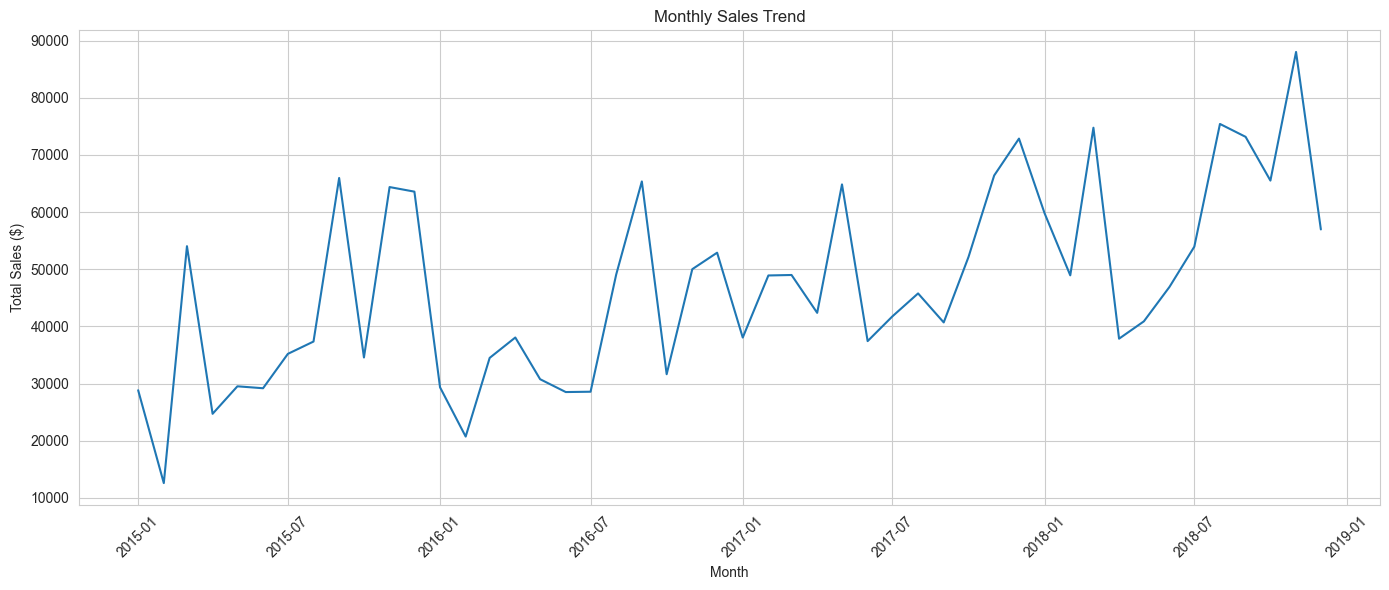

In [ ]:
# plot a line chart of monthly sales
monthly_sales = sales_over_time.sort_index()

monthly_sales_plot = monthly_sales.copy()
monthly_sales_plot.index = monthly_sales_plot.index.to_timestamp()

plt.figure(figsize=(14, 6))
plt.plot(monthly_sales_plot.index, monthly_sales_plot.values)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


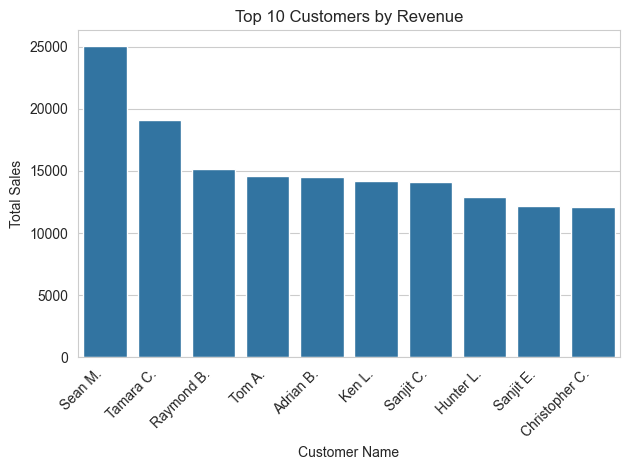

In [113]:
# Top 10 Customers by revenue
top_customers_revenue = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending = False).head(10)
print(top_customers_revenue)

# Create a DataFrame for plotting with formatted names
plot_df = top_customers_revenue.reset_index()
plot_df["Customer Name Formatted"] = plot_df["Customer Name"].apply(
    lambda name: f"{name.split()[0]} {name.split()[-1][0]}."
)

#Visualize Top 10 Customers by Revenue
sns.barplot(data=plot_df, x="Customer Name Formatted", y="Sales")
plt.xlabel("Customer Name")
plt.ylabel("Total Sales")
plt.title("Top 10 Customers by Revenue")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Conclusion

This project explored sales data using Python, Pandas, Matplotlib, and Seaborn to identify trends and compare business performance.

Key findings:
- **Regional performance:** The West region generated the highest sales, at approximately $710,219.68.
- **Product categories:** Technology generated the highest total sales, at approximately $827,455.87, while Office Supplies generated approximately $705,422.33.
- **Customer analysis:** The top 10 customers were identified based on total sales revenue.
- **Monthly trends:** Monthly sales fluctuated over time, with the highest monthly sales recorded in November 2018 and the lowest in February 2015.

This analysis demonstrates how data cleaning, aggregation, and visualization can be used to summarize sales performance and identify patterns worth investigating further.

**Limitations:** The analysis identifies patterns in historical sales but does not establish the causes of changes or measure profitability.